# Task 42: Training and Validation Loss Curves

Record binary cross-entropy each epoch for training and validation data, plot the histories using Matplotlib axes, and interpret convergence and overfitting trends.

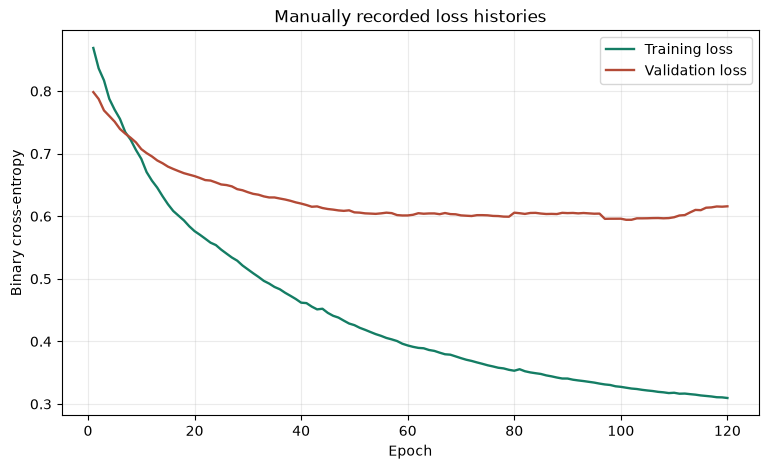

Epochs: 120 best validation epoch: 101 minimum validation loss: 0.5943
Final train/validation losses: 0.3096 0.6159
Held-out test metrics: {'accuracy': 0.8524590163934426, 'precision': 0.9, 'recall': 0.8181818181818182}
A widening train/validation loss gap suggests overfitting; both curves flattening at high loss suggests underfitting. Test data did not select the epoch.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

candidates=[Path('heart.csv'),Path('Task_42_Training_Validation_Loss_Curves/heart.csv'),Path('Heart_Disease_Tasks/Task_42_Training_Validation_Loss_Curves/heart.csv')]
data=pd.read_csv(next(p for p in candidates if p.is_file())).drop_duplicates().reset_index(drop=True)
features=[c for c in ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal'] if c in data]
X,y=data[features].to_numpy(float),data.target.to_numpy(int)
rng=np.random.default_rng(42); train_val=[]; test=[]
for label in np.unique(y):
    ids=np.flatnonzero(y==label);rng.shuffle(ids);cut=round(.8*len(ids));train_val.extend(ids[:cut]);test.extend(ids[cut:])
train_val=np.array(train_val);test=np.array(test);rng.shuffle(train_val);rng.shuffle(test)
rng=np.random.default_rng(43); train=[];validation=[]
for label in np.unique(y[train_val]):
    ids=train_val[y[train_val]==label];rng.shuffle(ids);cut=round(.8*len(ids));train.extend(ids[:cut]);validation.extend(ids[cut:])
train=np.array(train);validation=np.array(validation)
X_train,X_val,X_test=X[train],X[validation],X[test];y_train,y_val,y_test=y[train],y[validation],y[test]
mean,scale=X_train.mean(0),X_train.std(0);scale[scale==0]=1
X_train,X_val,X_test=(X_train-mean)/scale,(X_val-mean)/scale,(X_test-mean)/scale


def sigmoid(z):return 1/(1+np.exp(-np.clip(z,-35,35)))

class TrackedMLP:
    def __init__(self,hidden=(24,12),seed=42):self.hidden,self.seed=hidden,seed
    def fit(self,x,y,x_val,y_val,epochs=120,rate=.008,batch=32):
        rng=np.random.default_rng(self.seed);dims=(x.shape[1],*self.hidden,1)
        self.w=[rng.normal(0,np.sqrt(2/dims[i]),(dims[i],dims[i+1])) for i in range(len(dims)-1)];self.b=[np.zeros((1,dims[i+1])) for i in range(len(dims)-1)]
        self.train_loss=[];self.validation_loss=[];targets=y[:,None]
        for _ in range(epochs):
            order=rng.permutation(len(x));epoch_loss=0.
            for start in range(0,len(x),batch):
                ids=order[start:start+batch];a=[x[ids]]
                for layer in range(len(self.hidden)):a.append(np.maximum(a[-1]@self.w[layer]+self.b[layer],0))
                p=sigmoid(a[-1]@self.w[-1]+self.b[-1]);yy=targets[ids]
                epoch_loss+=float(-np.sum(yy*np.log(p+1e-12)+(1-yy)*np.log(1-p+1e-12)))
                grad=(p-yy)/len(ids);dw=[None]*len(self.w);db=[None]*len(self.b)
                dw[-1]=a[-1].T@grad;db[-1]=grad.sum(0,keepdims=True);grad=grad@self.w[-1].T
                for layer in range(len(self.hidden)-1,-1,-1):
                    grad*=a[layer+1]>0;dw[layer]=a[layer].T@grad;db[layer]=grad.sum(0,keepdims=True);grad=grad@self.w[layer].T
                for layer in range(len(self.w)):self.w[layer]-=rate*dw[layer];self.b[layer]-=rate*db[layer]
            self.train_loss.append(epoch_loss/len(x))
            self.validation_loss.append(self.loss(x_val,y_val))
        return self
    def probabilities(self,x):
        a=x
        for layer in range(len(self.hidden)):a=np.maximum(a@self.w[layer]+self.b[layer],0)
        return sigmoid(a@self.w[-1]+self.b[-1]).ravel()
    def loss(self,x,y):
        p=np.clip(self.probabilities(x),1e-12,1-1e-12)
        return float(-np.mean(y*np.log(p)+(1-y)*np.log(1-p)))

model=TrackedMLP().fit(X_train,y_train,X_val,y_val)
fig,ax=plt.subplots(figsize=(9,5));epochs=np.arange(1,len(model.train_loss)+1)
ax.plot(epochs,model.train_loss,color='#147d64',linewidth=1.7,label='Training loss');ax.plot(epochs,model.validation_loss,color='#b34a36',linewidth=1.7,label='Validation loss')
ax.set_xlabel('Epoch');ax.set_ylabel('Binary cross-entropy');ax.set_title('Manually recorded loss histories');ax.legend();ax.grid(True,alpha=.25);plt.show()
best_epoch=int(np.argmin(model.validation_loss))+1
print('Epochs:',len(epochs),'best validation epoch:',best_epoch,'minimum validation loss:',round(min(model.validation_loss),4))
print('Final train/validation losses:',round(model.train_loss[-1],4),round(model.validation_loss[-1],4))
pred=(model.probabilities(X_test)>=.5).astype(int);tp=np.sum((y_test==1)&(pred==1));tn=np.sum((y_test==0)&(pred==0));fp=np.sum((y_test==0)&(pred==1));fn=np.sum((y_test==1)&(pred==0))
precision=tp/(tp+fp) if tp+fp else 0;recall=tp/(tp+fn) if tp+fn else 0
print('Held-out test metrics:',{'accuracy':float((tp+tn)/len(y_test)),'precision':float(precision),'recall':float(recall)})
print('A widening train/validation loss gap suggests overfitting; both curves flattening at high loss suggests underfitting. Test data did not select the epoch.')